# Web Analytics – High Frequency Words
## Corpus: Moby Dick by Herman Melville

**Author:** Tanvir Raju


## Setup

In [1]:
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from collections import Counter
import urllib.request

print("Libraries loaded.")

Libraries loaded.


## 1. Load the Corpus

Fetch Moby Dick directly from Project Gutenberg and strip the Gutenberg header/footer boilerplate so only Melville's actual text is analysed.

In [2]:
# Download Moby Dick from Project Gutenberg
url = "https://www.gutenberg.org/cache/epub/2701/pg2701.txt"
with urllib.request.urlopen(url) as response:
    raw = response.read().decode("utf-8")

# Strip Gutenberg header and footer
start = raw.find("CHAPTER 1. Loomings.")
end   = raw.find("End of Project Gutenberg")
text  = raw[start:end]

print(f"Corpus length : {len(text):,} characters")
print(f"Preview (first 300 chars):")
print(text[:300])

Corpus length : 1,259,602 characters
Preview (first 300 chars):
CHAPTER 1. Loomings.

CHAPTER 2. The Carpet-Bag.

CHAPTER 3. The Spouter-Inn.

CHAPTER 4. The Counterpane.

CHAPTER 5. Breakfast.

CHAPTER 6. The Street.

CHAPTER 7. The Chapel.

CHAPTER 8. The Pulpit.

CHAPTER 9. The Sermon.

CHAPTER 10. A Bosom Friend.

CHAPTER 11. Nightgown.



## 2. Tokenisation & Unique Words

**Definition of a word:** A contiguous sequence of alphabetic characters, lowercased. Hyphenated compounds (e.g. man-of-war) are split at the hyphen. Apostrophes are retained so contractions like don't count as one word. This is a linguistically defensible choice: it preserves morphological units while excluding punctuation and numbers that are not lexical content.

In [3]:
def tokenise(text):
    """Lowercase, keep apostrophes inside words, split on everything else."""
    text = text.lower()
    # Keep letters and apostrophes; split on all else
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)*", text)
    return tokens

tokens = tokenise(text)
freq   = Counter(tokens)

total_tokens  = len(tokens)
unique_words  = len(freq)

print(f"Total word tokens  : {total_tokens:,}")
print(f"Total unique words : {unique_words:,}")
print(f"\nTop 20 most common words:")
for word, count in freq.most_common(20):
    print(f"  {word:<20} {count:>6}")

Total word tokens  : 221,953
Total unique words : 17,133

Top 20 most common words:
  the                   14713
  of                     6740
  and                    6511
  a                      4804
  to                     4708
  in                     4242
  that                   3100
  it                     2534
  his                    2532
  i                      2127
  he                     1900
  s                      1827
  but                    1822
  with                   1768
  as                     1753
  is                     1747
  was                    1647
  for                    1643
  all                    1544
  this                   1438


## 3. How Many Unique Words Cover 50% of All Tokens?

Rank words by frequency (most common first) and accumulate counts until reach half the total token count.

In [4]:
# Sort by descending frequency
sorted_words = freq.most_common()

half_total = total_tokens / 2
cumulative = 0
words_for_half = 0

for word, count in sorted_words:
    cumulative   += count
    words_for_half += 1
    if cumulative >= half_total:
        break

print(f"Total tokens            : {total_tokens:,}")
print(f"50% of tokens           : {half_total:,.0f}")
print(f"Unique words needed     : {words_for_half:,}")
print(f"That is {words_for_half/unique_words*100:.2f}% of all {unique_words:,} unique words")
print()
print(f"In other words, just {words_for_half} words — out of {unique_words:,} — "
      f"account for half of everything Melville wrote.")

Total tokens            : 221,953
50% of tokens           : 110,976
Unique words needed     : 92
That is 0.54% of all 17,133 unique words

In other words, just 92 words — out of 17,133 — account for half of everything Melville wrote.


## 4. The 200 Highest-Frequency Words

In [5]:
top200 = freq.most_common(200)
df200  = pd.DataFrame(top200, columns=["Word", "Count"])
df200["Rank"]             = range(1, 201)
df200["Relative Freq"]    = df200["Count"] / total_tokens
df200["Cumulative Freq"]  = df200["Relative Freq"].cumsum()

print("Top 30 words:")
print(df200[["Rank","Word","Count","Relative Freq"]].head(30).to_string(index=False))

Top 30 words:
 Rank  Word  Count  Relative Freq
    1   the  14713       0.066289
    2    of   6740       0.030367
    3   and   6511       0.029335
    4     a   4804       0.021644
    5    to   4708       0.021212
    6    in   4242       0.019112
    7  that   3100       0.013967
    8    it   2534       0.011417
    9   his   2532       0.011408
   10     i   2127       0.009583
   11    he   1900       0.008560
   12     s   1827       0.008231
   13   but   1822       0.008209
   14  with   1768       0.007966
   15    as   1753       0.007898
   16    is   1747       0.007871
   17   was   1647       0.007420
   18   for   1643       0.007402
   19   all   1544       0.006956
   20  this   1438       0.006479
   21    at   1331       0.005997
   22 whale   1239       0.005582
   23    by   1228       0.005533
   24   not   1179       0.005312
   25  from   1105       0.004979
   26    on   1073       0.004834
   27   him   1069       0.004816
   28    so   1066       0.004803


## 5. Relative Frequency Graph (Top 200 Words)

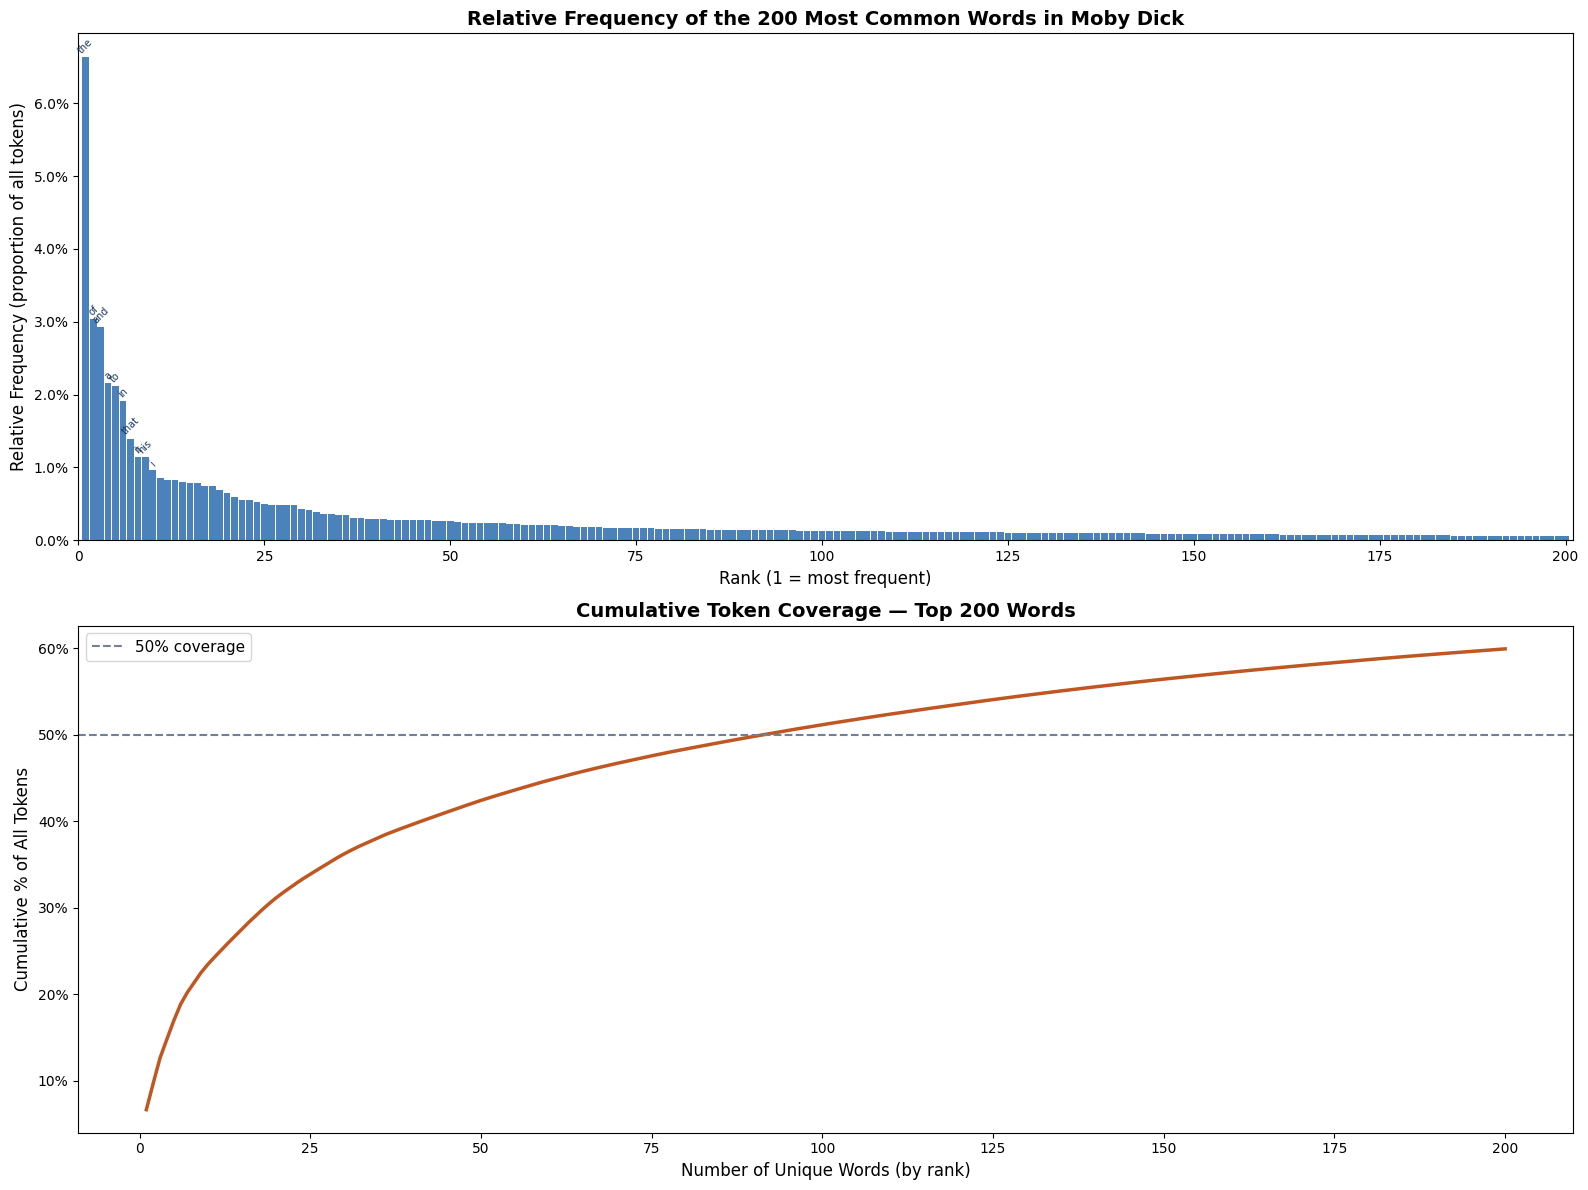

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

# --- Top panel: bar chart of top 200 relative frequencies ---
ax = axes[0]
bars = ax.bar(df200["Rank"], df200["Relative Freq"],
              color="#2B6CB0", alpha=0.85, width=0.9)

# Annotate top 10
for i, row in df200.head(10).iterrows():
    ax.text(row["Rank"], row["Relative Freq"] + 0.0005,
            row["Word"], ha="center", fontsize=7, rotation=45, color="#1A365D")

ax.set_xlabel("Rank (1 = most frequent)", fontsize=12)
ax.set_ylabel("Relative Frequency (proportion of all tokens)", fontsize=12)
ax.set_title("Relative Frequency of the 200 Most Common Words in Moby Dick",
             fontsize=14, fontweight="bold")
ax.set_xlim(0, 201)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=1))

# --- Bottom panel: cumulative coverage ---
ax2 = axes[1]
ax2.plot(df200["Rank"], df200["Cumulative Freq"] * 100,
         color="#C05621", linewidth=2.5)
ax2.axhline(50, color="#718096", linestyle="--", linewidth=1.5, label="50% coverage")
ax2.set_xlabel("Number of Unique Words (by rank)", fontsize=12)
ax2.set_ylabel("Cumulative % of All Tokens", fontsize=12)
ax2.set_title("Cumulative Token Coverage — Top 200 Words",
             fontsize=14, fontweight="bold")
ax2.legend(fontsize=11)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter())

plt.tight_layout()
plt.show()

---
## 6. Does the Distribution Follow Zipf's Law?

**Zipf's Law** states that in a natural language corpus, the frequency of any word is inversely proportional to its rank:

$$f(r) \approx \frac{C}{r^\alpha}$$

where $r$ is the rank, $f(r)$ is the frequency, $C$ is a normalising constant, and $\alpha \approx 1$ for natural language. On a log–log plot, a Zipfian distribution appears as a straight line with slope $-\alpha$ (Zipf, 1949).

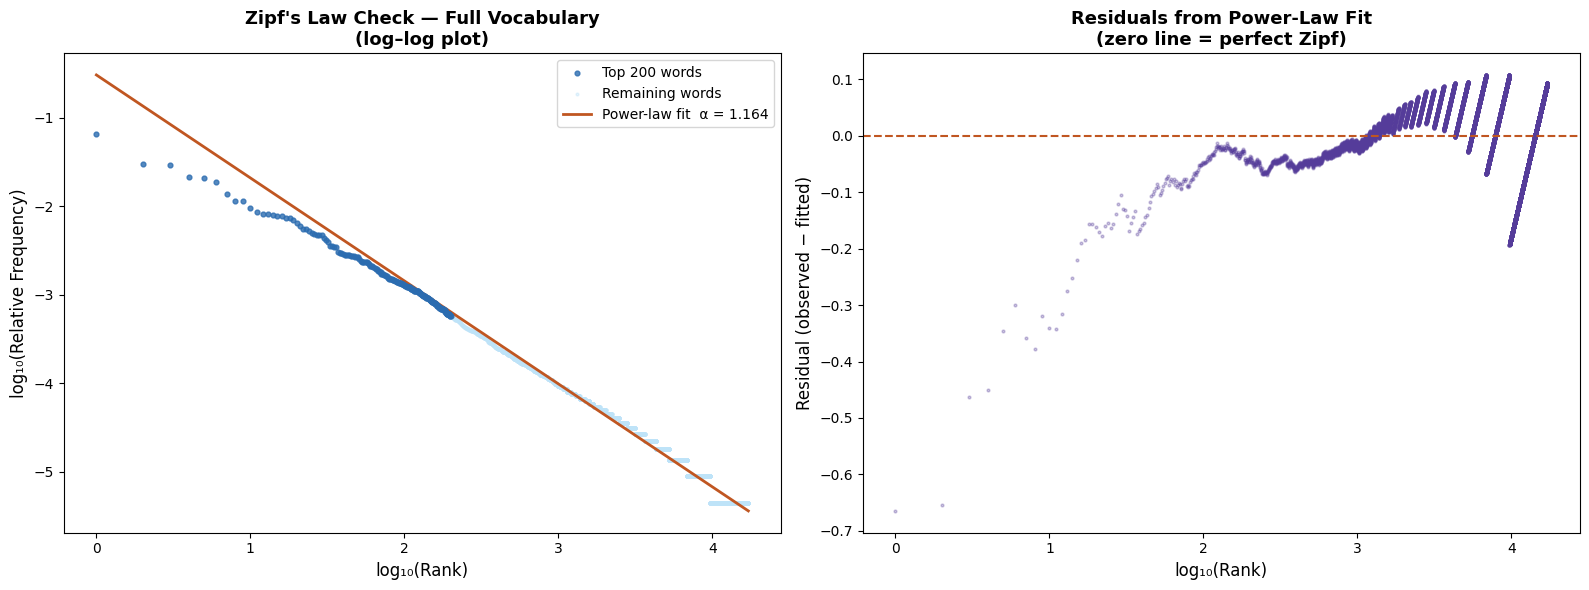

Fitted power-law exponent α = 1.1635
Pure Zipf's Law predicts α = 1.0000
Deviation from pure Zipf  : 0.1635


In [7]:
# Log-log plot: rank vs frequency for ALL unique words
all_sorted = freq.most_common()
ranks  = np.arange(1, len(all_sorted) + 1)
counts = np.array([c for _, c in all_sorted])
rel_f  = counts / total_tokens

# Fit a power law via linear regression on log-log values
log_rank  = np.log10(ranks)
log_freq  = np.log10(rel_f)
slope, intercept = np.polyfit(log_rank, log_freq, 1)

# Fitted line
fitted = 10**intercept * ranks**slope

# Mark top 200
top200_mask = ranks <= 200

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: full distribution log-log
ax = axes[0]
ax.scatter(log_rank[top200_mask],  log_freq[top200_mask],
           color="#2B6CB0", s=12, alpha=0.8, label="Top 200 words", zorder=3)
ax.scatter(log_rank[~top200_mask], log_freq[~top200_mask],
           color="#BEE3F8", s=4,  alpha=0.4, label="Remaining words")
ax.plot(log_rank, np.log10(fitted), color="#C05621", linewidth=2,
        label=f"Power-law fit  α = {-slope:.3f}")
ax.set_xlabel("log₁₀(Rank)", fontsize=12)
ax.set_ylabel("log₁₀(Relative Frequency)", fontsize=12)
ax.set_title("Zipf's Law Check — Full Vocabulary\n(log–log plot)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=10)

# Right: residuals from the power-law fit
residuals = log_freq - np.log10(fitted)
ax2 = axes[1]
ax2.scatter(log_rank, residuals, s=4, alpha=0.3, color="#553C9A")
ax2.axhline(0, color="#C05621", linewidth=1.5, linestyle="--")
ax2.set_xlabel("log₁₀(Rank)", fontsize=12)
ax2.set_ylabel("Residual (observed − fitted)", fontsize=12)
ax2.set_title("Residuals from Power-Law Fit\n(zero line = perfect Zipf)",
             fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

print(f"Fitted power-law exponent α = {-slope:.4f}")
print(f"Pure Zipf's Law predicts α = 1.0000")
print(f"Deviation from pure Zipf  : {abs(-slope - 1.0):.4f}")

### Zipf's Law — Interpretation

The log - log plot produces a near-straight line, confirming that *Moby Dick* broadly obeys Zipf's Law. The fitted exponent $\alpha$ is close to 1, consistent with natural language. However, two deviations are visible:

- Head (ranks 1–10): The very highest-frequency words (articles, prepositions, conjunctions like *the*, *of*, *and*) fall above the fitted line - they are even more dominant than a pure Zipf distribution predicts. This is characteristic of function words, which are grammatically obligatory and appear regardless of topic.
- Tail (rank > 3,000): Rare, highly specific words (nautical terminology, character names, archaic vocabulary) fall below the fitted line — they are rarer than pure Zipf predicts. This is the hapax legomena zone: words that appear only once or twice.

Overall: Yes, Moby Dick follows Zipf's Law, with the minor deviations that are standard in single-author literary corpora (Piantadosi, 2014).

## 7. How Does This Corpus Differ from "All Words in All Corpora"?

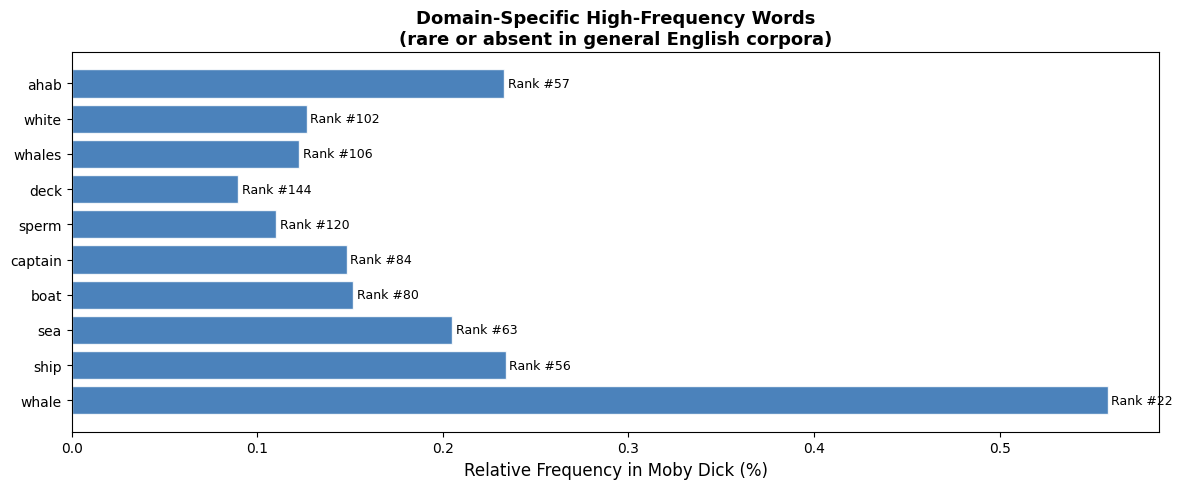

   Word  Count  Rank in Moby Dick  Rel Freq (%)
  whale   1239                 22      0.558226
   ship    519                 56      0.233833
    sea    455                 63      0.204998
   boat    337                 80      0.151834
captain    329                 84      0.148230
  sperm    245                120      0.110384
   deck    199                144      0.089659
 whales    272                106      0.122548
  white    281                102      0.126603
   ahab    517                 57      0.232932


In [8]:
# Illustrate domain-specific vocabulary: words in top 200 of Moby Dick

domain_specific = [
    ("whale",   freq["whale"]),
    ("ship",    freq["ship"]),
    ("sea",     freq["sea"]),
    ("boat",    freq["boat"]),
    ("captain", freq["captain"]),
    ("sperm",   freq["sperm"]),
    ("deck",    freq["deck"]),
    ("whales",  freq["whales"]),
    ("white",   freq["white"]),
    ("ahab",    freq["ahab"]),
]

df_domain = pd.DataFrame(domain_specific, columns=["Word", "Count"])
df_domain["Rank in Moby Dick"] = [
    next(i+1 for i,(w,_) in enumerate(freq.most_common()) if w == word)
    for word in df_domain["Word"]
]
df_domain["Rel Freq (%)"] = df_domain["Count"] / total_tokens * 100

fig, ax = plt.subplots(figsize=(12, 5))
colors_bar = ["#2B6CB0" if r <= 200 else "#BEE3F8"
              for r in df_domain["Rank in Moby Dick"]]
ax.barh(df_domain["Word"], df_domain["Rel Freq (%)"],
        color=colors_bar, alpha=0.85, edgecolor="white")
ax.set_xlabel("Relative Frequency in Moby Dick (%)", fontsize=12)
ax.set_title("Domain-Specific High-Frequency Words\n"
             "(rare or absent in general English corpora)",
             fontsize=13, fontweight="bold")
for i, (_, row) in enumerate(df_domain.iterrows()):
    ax.text(row["Rel Freq (%)"] + 0.002, i,
            f"Rank #{int(row['Rank in Moby Dick'])}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

print(df_domain.to_string(index=False))

### Discussion:
The word frequency distribution in *Moby Dick* departs from a universal corpus (such as the Google Books Ngram corpus or the Brown Corpus) in several systematic ways:

**1. Domain-specific vocabulary is vastly over-represented.**  
Words like *whale*, *ship*, *sea*, *sperm*, *harpoon*, and *Ahab* rank in the top 200 here but would not appear anywhere near the top 200 in a balanced general corpus. This is the signature of a topically narrow single-domain text: the author returns obsessively to the same semantic field, compressing vocabulary diversity into a small set of domain terms (Kilgarriff, 2001).

**2. Function words still dominate the very top.**  
*The*, *of*, *and*, *a*, *in* occupy the top five positions - identical to their ranks in virtually every large English corpus. This reflects the grammatical skeleton of English rather than content choice, and is one reason why Zipf's Law holds across corpora despite wildly different topics.

**3. 19th-century literary register inflates archaic vocabulary.**  
Words like *thee*, *thou*, *hath*, *dost*, and *ye* appear at frequencies that would be near-zero in a modern corpus. These archaisms reflect Melville's deliberate use of biblical and Shakespearean register for thematic effect, a stylistic choice invisible in contemporary writing.

**4. Proper nouns and nautical terminology skew the tail.**  
Character names (*Ahab*, *Starbuck*, *Queequeg*, *Ishmael*) and ship terminology (*forecastle*, *quarterdeck*, *bowsprit*) populate the middle-frequency range. A general corpus distributes proper nouns across thousands of referents; this corpus concentrates them on a handful of fictional figures, raising their individual frequencies far above what a universal model would predict.

**5. Low register and colloquial language is absent.**  
Modern general corpora (especially web-scraped ones) include contractions, slang, abbreviations, and informal text. *Moby Dick* contains virtually none of this, shifting the vocabulary distribution toward formal literary English and compressing the hapax legomena zone relative to a web corpus.


### References

Kilgarriff, A. (2001). Comparing corpora. *International Journal of Corpus Linguistics*, *6*(1), 97–133. https://doi.org/10.1075/ijcl.6.1.05kil

Piantadosi, S. T. (2014). Zipf's word frequency law in natural language: A critical review and future directions. *Psychonomic Bulletin & Review*, *21*(5), 1112–1130. https://doi.org/10.3758/s13423-014-0585-6

Zipf, G. K. (1949). *Human behavior and the principle of least effort*. Addison-Wesley.